In [1]:
# Problem Statement:
# Develop an LSTM-based model for time-series forecasting
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [2]:
import kagglehub
path = kagglehub.dataset_download("vidhisrivastava/weather-dataset")

print("Path to dataset files:", path)

100%|██████████| 101k/101k [00:00<00:00, 33.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vidhisrivastava/weather-dataset/versions/1


In [3]:
print(os.listdir(path))

['Project1WeatherDataset.csv']


In [4]:

file_path = os.path.join(path, "Project1WeatherDataset.csv")

df = pd.read_csv(file_path)

print(df.head())
print("Original shape:", df.shape)
print(df.columns)

       Date/Time  Temp_C  Dew Point Temp_C  Rel Hum_%  Wind Speed_km/h  \
0  1/1/2012 0:00    -1.8              -3.9         86                4   
1  1/1/2012 1:00    -1.8              -3.7         87                4   
2  1/1/2012 2:00    -1.8              -3.4         89                7   
3  1/1/2012 3:00    -1.5              -3.2         88                6   
4  1/1/2012 4:00    -1.5              -3.3         88                7   

   Visibility_km  Press_kPa               Weather  
0            8.0     101.24                   Fog  
1            8.0     101.24                   Fog  
2            4.0     101.26  Freezing Drizzle,Fog  
3            4.0     101.27  Freezing Drizzle,Fog  
4            4.8     101.23                   Fog  
Original shape: (8784, 8)
Index(['Date/Time', 'Temp_C', 'Dew Point Temp_C', 'Rel Hum_%',
       'Wind Speed_km/h', 'Visibility_km', 'Press_kPa', 'Weather'],
      dtype='object')


In [5]:
df = df.head(1000).copy()

print("New dataset shape:", df.shape)

New dataset shape: (1000, 8)


In [6]:
print(df.isnull().sum())
print(df.describe())

Date/Time           0
Temp_C              0
Dew Point Temp_C    0
Rel Hum_%           0
Wind Speed_km/h     0
Visibility_km       0
Press_kPa           0
Weather             0
dtype: int64
            Temp_C  Dew Point Temp_C    Rel Hum_%  Wind Speed_km/h  \
count  1000.000000       1000.000000  1000.000000      1000.000000   
mean     -6.792300        -11.742500    68.441000        17.277000   
std       6.076123          6.835978    11.106299         9.994206   
min     -23.300000        -28.500000    39.000000         0.000000   
25%     -11.200000        -16.200000    60.000000         9.000000   
50%      -6.300000        -11.850000    69.000000        17.000000   
75%      -1.800000         -6.600000    78.000000        22.000000   
max       5.300000          3.600000    94.000000        83.000000   

       Visibility_km    Press_kPa  
count    1000.000000  1000.000000  
mean       22.615800   101.113710  
std        11.442274     0.965991  
min         0.600000    97.990000  


In [7]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"], errors="coerce")

df = df.sort_values("Date/Time")

df = df.dropna(subset=["Date/Time"])

print(df[["Date/Time"]].head())

            Date/Time
0 2012-01-01 00:00:00
1 2012-01-01 01:00:00
2 2012-01-01 02:00:00
3 2012-01-01 03:00:00
4 2012-01-01 04:00:00


In [8]:
temperature = df[["Temp_C"]].values

print(temperature[:5])
print("Number of records:", len(temperature))

[[-1.8]
 [-1.8]
 [-1.8]
 [-1.5]
 [-1.5]]
Number of records: 1000


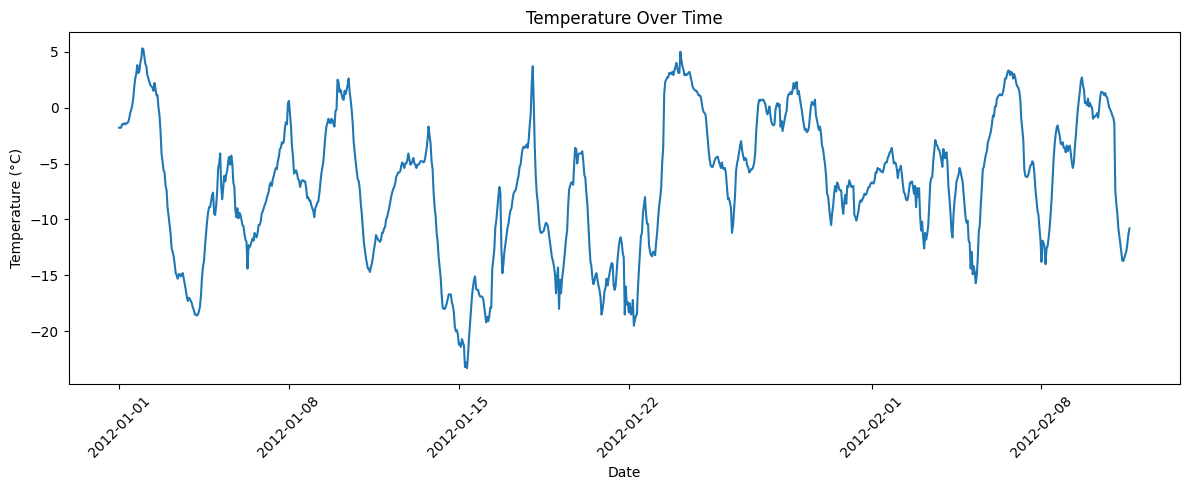

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date/Time"], df["Temp_C"])

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_temperature = scaler.fit_transform(temperature)

print(scaled_temperature[:5])

[[0.75174825]
 [0.75174825]
 [0.75174825]
 [0.76223776]
 [0.76223776]]


In [11]:
sequence_length = 24

X = []
y = []

for i in range(sequence_length, len(scaled_temperature)):
    X.append(scaled_temperature[i-sequence_length:i])
    y.append(scaled_temperature[i])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (976, 24, 1)
y shape: (976, 1)


In [12]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 780
Testing samples: 196


In [13]:
model = Sequential([
    LSTM(32, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.1280 - val_loss: 0.0273
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0216 - val_loss: 0.0166
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0181 - val_loss: 0.0151
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0160 - val_loss: 0.0138
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0136 - val_loss: 0.0123
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0139 - val_loss: 0.0112
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0123 - val_loss: 0.0104
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0116 - val_loss: 0.0091
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0100 - val_loss: 0.0084
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0096 - val_loss: 0.0078


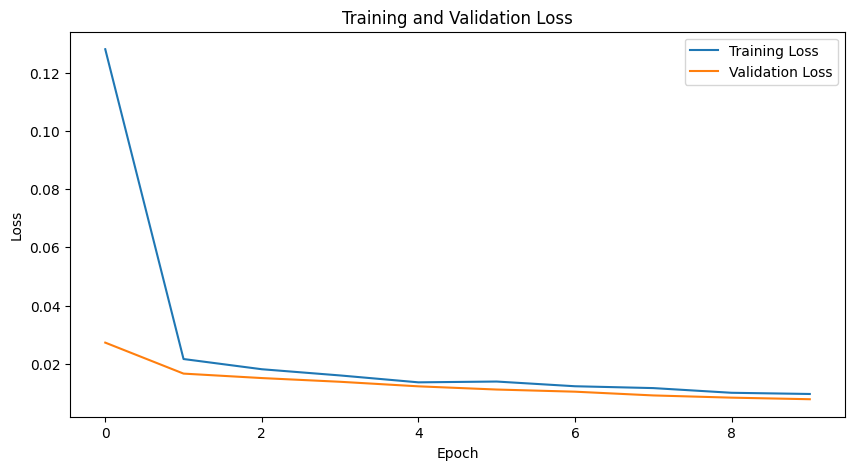

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

In [16]:
predictions = model.predict(X_test)

print("Prediction shape:", predictions.shape)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Prediction shape: (196, 1)


In [18]:
predicted_temperature = scaler.inverse_transform(predictions)
actual_temperature = scaler.inverse_transform(y_test)

print("Predicted:", predicted_temperature[:5].flatten())
print("Actual:", actual_temperature[:5].flatten())

Predicted: [-9.689435  -8.965837  -8.129912  -7.221751  -6.2767463]
Actual: [-6.2 -4.8 -3.8 -2.9 -3.3]


In [19]:
mae = mean_absolute_error(
    actual_temperature,
    predicted_temperature
)

rmse = np.sqrt(
    mean_squared_error(
        actual_temperature,
        predicted_temperature
    )
)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Absolute Error (MAE): 1.9922695772247196
Root Mean Squared Error (RMSE): 2.530124940338832


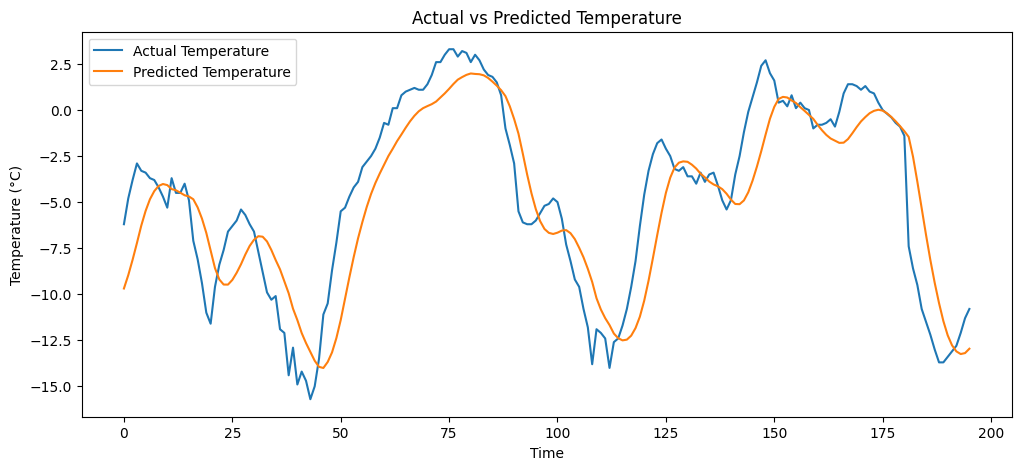

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(actual_temperature, label="Actual Temperature")
plt.plot(predicted_temperature, label="Predicted Temperature")

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Predicted Temperature")

plt.legend()
plt.show()

In [21]:
def train_lstm(epochs):

    model = Sequential([
        LSTM(32, input_shape=(X_train.shape[1], X_train.shape[2])),
        Dropout(0.2),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=32,
        verbose=0
    )

    predictions = model.predict(X_test, verbose=0)

    predictions = scaler.inverse_transform(predictions)

    mae = mean_absolute_error(
        actual_temperature,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_temperature,
            predictions
        )
    )

    return mae, rmse

In [22]:
results = []

for epochs in [10, 20, 30]:

    mae, rmse = train_lstm(epochs)

    results.append({
        "Epochs": epochs,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

print(results_df)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Epochs       MAE      RMSE
0      10  2.090070  2.646986
1      20  1.962737  2.400564
2      30  1.422427  1.852267
